# Klasifikasi Tutupan Lahan Jawa Timur dengan Sentinel-2A dan Random Forest

## Tujuan proyek

Proyek ini mencoba mengelompokkan tutupan lahan menjadi lima kelas: `build up`, `farm land`, `water body`, `forest`, dan `mangrove`. Sampel kelas berasal dari polygon GeoJSON yang didigitasi, sedangkan nilai spektralnya diambil dari citra Sentinel-2 Level-2A. Model yang digunakan dalam notebook ini adalah Random Forest.

Hasil yang dituju adalah raster klasifikasi dan peta untuk memeriksa hasilnya. Kualitas hasil perlu dilihat dari metrik pengujian dan pemeriksaan visual, bukan hanya dari tampilan peta.

**Batasan wilayah:** file `jawatimur.geojson` yang digunakan di sini berisi polygon sampel, bukan batas administrasi Provinsi Jawa Timur. Karena itu, hasil raster belum otomatis terbatas pada wilayah daratan Jawa Timur. Jika ingin menghitung statistik resmi per provinsi atau menghilangkan laut di luar area yang diteliti, gunakan batas administrasi/mask wilayah yang sesuai dan tetap pertahankan sampel mangrove pesisir.

## Urutan pengerjaan

1. Membaca GeoJSON dan memeriksa file citra.
2. Melihat sampel pada citra dan peta interaktif.
3. Mengambil nilai sepuluh band untuk tiap polygon.
4. Membersihkan data, melatih Random Forest, lalu mengevaluasi hasilnya.
5. Menerapkan model ke raster dan menyimpan GeoTIFF.
6. Memeriksa peta hasil. Dashboard Streamlit memerlukan file aplikasi `app.py` terpisah.

## Revisi penting: cakupan citra dan mosaik

**Penting:** satu tile TIFF per band tidak dapat mencakup seluruh Provinsi Jawa Timur. Notebook ini disiapkan agar dapat menggabungkan semua tile yang telah diunduh untuk setiap band. Simpan semua tile mentah di folder `data` dan gunakan nama file asli Copernicus yang mengandung kode band, misalnya `B02_(Raw)`, `B03_(Raw)`, dan seterusnya.

Mosaik hanya menggabungkan cakupan tile yang benar-benar tersedia; mosaik tidak dapat mengisi area yang belum diunduh. Setelah menambahkan tile baru, jalankan ulang sel pembuatan mosaik dan sel-sel sesudahnya. Pastikan juga tersedia batas administrasi Jawa Timur terpisah dari 250 poligon sampel agar raster akhir bisa dipotong tepat ke AOI.

Label kelas pada GeoJSON sampel tetap dipertahankan sebagai lima kelas: `build up`, `fram land`/`farm land`, `water body`, `forest`, dan `hutan mangrove`/`mangrove`.


## Cell 1 — Menyiapkan proyek

Di bagian ini saya memanggil pustaka yang dibutuhkan untuk membaca data, mengolah angka, memproses GeoJSON dan raster, serta membuat visualisasi. `BASE_DIR` mengikuti folder tempat notebook dijalankan. Folder `data` dipakai untuk menyimpan citra dan GeoJSON, sedangkan hasil pengolahan disimpan di `output`.

Kode juga mengecek apakah folder data tersedia dan menampilkan file di dalamnya. Pengecekan ini membantu menemukan masalah nama atau lokasi file sebelum analisis dimulai.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt
import folium

# Folder utama proyek
BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "data"
OUTPUT_DIR = BASE_DIR / "output"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Folder utama :", BASE_DIR)
print("Folder data  :", DATA_DIR)
print("Folder output:", OUTPUT_DIR)

assert DATA_DIR.exists(), "Folder data tidak ditemukan!"

print("\nFile dalam folder data:")
for file in sorted(DATA_DIR.iterdir()):
    print("-", file.name)


Folder utama : d:\semester 5\PROYEK SAINS DATA\LULC_JAWA_TIMUR\LULC JAWA TIMUR
Folder data  : d:\semester 5\PROYEK SAINS DATA\LULC_JAWA_TIMUR\LULC JAWA TIMUR\data
Folder output: d:\semester 5\PROYEK SAINS DATA\LULC_JAWA_TIMUR\LULC JAWA TIMUR\output


AssertionError: Folder data tidak ditemukan!

## Cell 2 — Membaca sampel GeoJSON

Cell ini membaca polygon hasil digitasi dari `jawatimur.geojson`. Kolom yang berisi nama kelas diambil dari atribut yang tersedia, lalu penulisannya diseragamkan supaya label seperti `fram land` tidak dianggap sebagai kelas berbeda dari `farm land`.

Setelah itu, hanya lima kelas tugas yang dipakai: `build up`, `farm land`, `water body`, `forest`, dan `mangrove`. Label yang tidak sesuai daftar tidak ikut masuk ke dataset model. Jumlah tiap kelas ditampilkan supaya distribusi sampel bisa diperiksa.

In [ ]:
geojson_path = DATA_DIR / "jawatimur.geojson"
if not geojson_path.exists():
    raise FileNotFoundError(f"GeoJSON sampel tidak ditemukan: {geojson_path}")

gdf = gpd.read_file(geojson_path)
if gdf.crs is None:
    raise ValueError("GeoJSON tidak memiliki CRS.")
gdf = gdf.to_crs("EPSG:4326").copy()

kolom_label = next((c for c in ["nama", "class", "kelas", "name"] if c in gdf.columns), None)
if kolom_label is None:
    raise ValueError("Kolom label kelas tidak ditemukan di GeoJSON.")
gdf["class"] = (
    gdf[kolom_label].astype(str).str.strip().str.lower().replace({
        "fram land": "farm land",
        "farmland": "farm land",
        "farmland ": "farm land",
        "built-up": "build up",
        "built up": "build up",
        "hutan mangrove": "mangrove",
        "waterbody": "water body",
        "none": "unknown"
    })
)

kelas_diizinkan = ["build up", "farm land", "water body", "forest", "mangrove"]
gdf = gdf[gdf["class"].isin(kelas_diizinkan)].copy()
print("Jumlah polygon sampel:", len(gdf))
print("Distribusi kelas:")
display(gdf["class"].value_counts().rename("jumlah").to_frame())
gdf.head()


Jumlah polygon sampel: 261
Distribusi kelas:


,jumlah
class,
farm land,61
build up,50
mangrove,50
water body,50
forest,50


,nama,visibility,geometry,class
0,build up,NaN,"POLYGON ((113.54707 -7.03551, 113.54705 -7.035...",build up
1,build up,NaN,"POLYGON ((113.54704 -7.03574, 113.54696 -7.036...",build up
2,build up,NaN,"POLYGON ((113.5465 -7.03616, 113.54694 -7.0362...",build up
3,build up,NaN,"POLYGON ((113.54516 -7.03492, 113.54498 -7.034...",build up
4,build up,NaN,"POLYGON ((113.54661 -7.03532, 113.5465 -7.0355...",build up


## Cell 3 — Memeriksa file citra

Cell ini membaca metadata semua file TIFF di folder data. Informasi yang ditampilkan mencakup CRS, ukuran raster, resolusi, jumlah band, dan batas cakupan citra.

Pemeriksaan ini berguna sebelum band digabungkan. Band Sentinel-2 tidak selalu memiliki resolusi yang sama, jadi dimensi dan transformasinya perlu diperiksa sebelum dipakai untuk klasifikasi per piksel.

In [ ]:

tiff_files = sorted(
    list(DATA_DIR.glob("*.tif")) +
    list(DATA_DIR.glob("*.tiff"))
)

for file in tiff_files:
    with rasterio.open(file) as src:
        print(f"\n{file.name}")
        print("CRS       :", src.crs)
        print("Dimensi   :", src.width, "x", src.height)
        print("Resolusi  :", src.res)
        print("Jumlah band:", src.count)
        print("Bounds    :", src.bounds)



2026-10-01-00_00_2026-10-01-23_59_Sentinel-2_L2A_B02_(Raw).tiff
CRS       : EPSG:4326
Dimensi   : 2500 x 1487
Resolusi  : (0.0012224333599999966, 0.001212031809011432)
Jumlah band: 1
Bounds    : BoundingBox(left=111.4126454, bottom=-8.4407652, right=114.4687288, top=-6.6384739)

2026-10-01-00_00_2026-10-01-23_59_Sentinel-2_L2A_B03_(Raw).tiff
CRS       : EPSG:4326
Dimensi   : 2500 x 1487
Resolusi  : (0.0012224333599999966, 0.001212031809011432)
Jumlah band: 1
Bounds    : BoundingBox(left=111.4126454, bottom=-8.4407652, right=114.4687288, top=-6.6384739)

2026-10-01-00_00_2026-10-01-23_59_Sentinel-2_L2A_B04_(Raw).tiff
CRS       : EPSG:4326
Dimensi   : 2500 x 1487
Resolusi  : (0.0012224333599999966, 0.001212031809011432)
Jumlah band: 1
Bounds    : BoundingBox(left=111.4126454, bottom=-8.4407652, right=114.4687288, top=-6.6384739)

2026-10-01-00_00_2026-10-01-23_59_Sentinel-2_L2A_B05_(Raw).tiff
CRS       : EPSG:4326
Dimensi   : 2500 x 1487
Resolusi  : (0.0012224333599999966, 0.00121203180

## Cell 4 — Menampilkan citra True Color

Cell ini mencari file True Color, membaca tiga band pertamanya, lalu menyesuaikan rentang nilai piksel agar gambar lebih jelas dilihat. Penyesuaian ini hanya untuk tampilan, bukan mengubah file sumber.

Citra ditampilkan menggunakan Matplotlib sebagai gambaran awal wilayah yang dianalisis. Jika file tidak ditemukan, pola pencarian nama file perlu disesuaikan dengan nama TIFF di folder data.

File: 2026-10-01-00_00_2026-10-01-23_59_Sentinel-2_L2A_True_color.tiff
CRS: EPSG:4326
Dimensi: 2500 x 1487
Jumlah band: 3
Rentang nilai: 0.0 - 65495.0


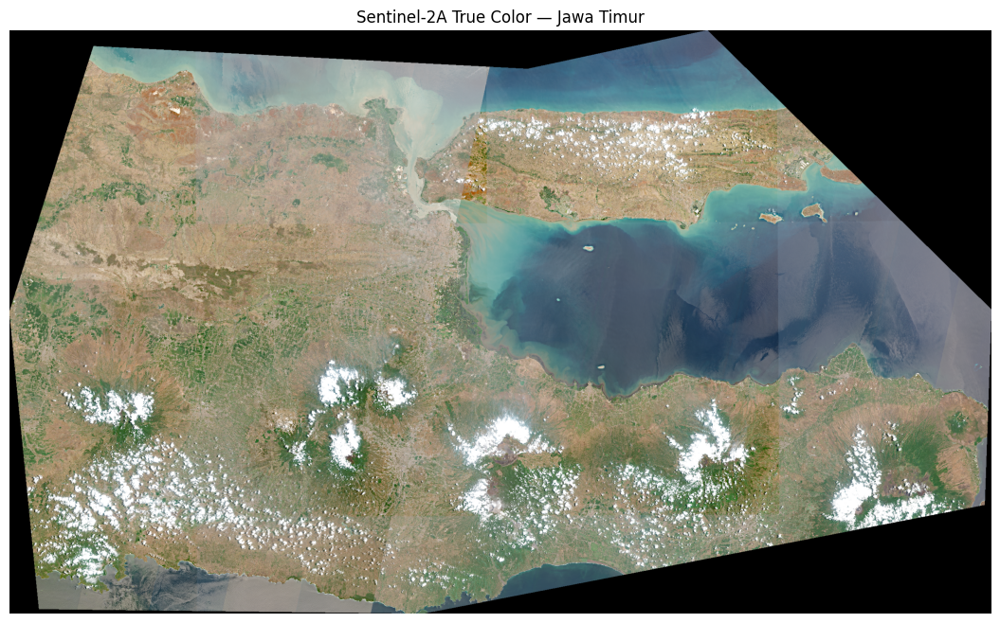

In [ ]:

from pathlib import Path
import numpy as np
import rasterio
import matplotlib.pyplot as plt

truecolor_candidates = sorted(
    list(DATA_DIR.glob("*True*color*.tif")) +
    list(DATA_DIR.glob("*True*color*.tiff"))
)
truecolor_path = truecolor_candidates[0] if truecolor_candidates else None

if truecolor_path is None:
    raise FileNotFoundError("File True Color tidak ditemukan.")

with rasterio.open(truecolor_path) as src:
    # Baca tiga kanal RGB
    rgb = src.read([1, 2, 3]).astype(np.float32)

    print("File:", truecolor_path.name)
    print("CRS:", src.crs)
    print("Dimensi:", src.width, "x", src.height)
    print("Jumlah band:", src.count)
    print("Rentang nilai:", np.nanmin(rgb), "-", np.nanmax(rgb))

# Normalisasi untuk visualisasi
rgb_display = np.zeros_like(rgb)

for i in range(3):
    band = rgb[i]
    p2, p98 = np.nanpercentile(band, [2, 98])

    if p98 > p2:
        rgb_display[i] = np.clip(
            (band - p2) / (p98 - p2), 0, 1
        )

rgb_display = np.moveaxis(rgb_display, 0, -1)

plt.figure(figsize=(14, 8))
plt.imshow(rgb_display)
plt.title("Sentinel-2A True Color — Jawa Timur")
plt.axis("off")
plt.show()


## Cell 5 — Mengecek posisi polygon

Di sini polygon GeoJSON ditumpangkan pada citra True Color untuk mengecek apakah posisi sampel masuk akal. Langkah ini penting agar sampel yang digunakan untuk melatih model benar-benar berada pada objek yang dimaksud.

Citra dan polygon harus ditampilkan dalam CRS yang sama. Jika CRS berbeda, salah satunya perlu dikonversi sebelum dibuat plot.

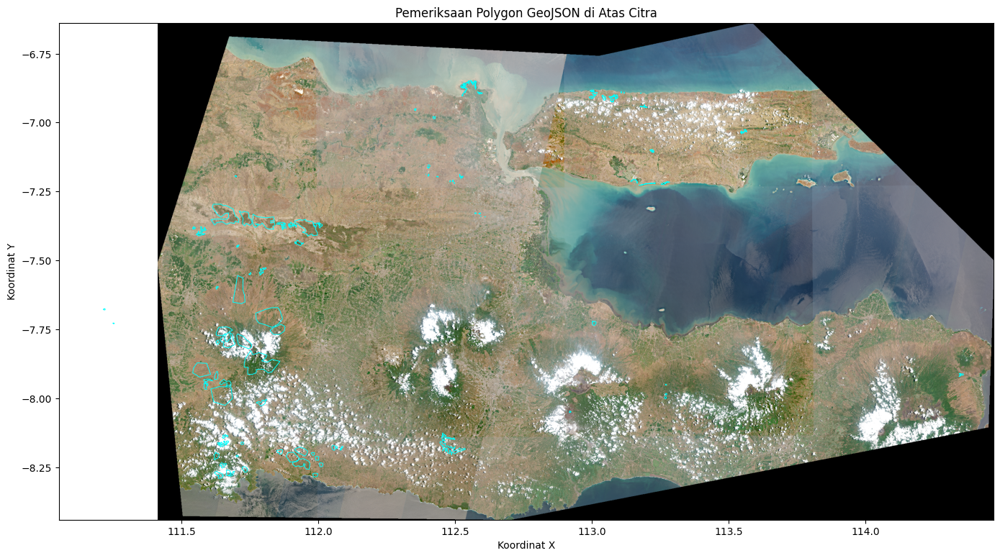

In [ ]:
fig, ax = plt.subplots(figsize=(14, 9))

with rasterio.open(truecolor_path) as src:
    rgb = src.read([1, 2, 3]).astype(np.float32)
    bounds = src.bounds
    raster_crs = src.crs

    rgb_display_plot = np.zeros_like(rgb, dtype=np.float32)
    for i in range(3):
        band = rgb[i]
        valid = band[np.isfinite(band)]
        if valid.size:
            p2, p98 = np.percentile(valid, [2, 98])
            if p98 > p2:
                rgb_display_plot[i] = np.clip(
                    (band - p2) / (p98 - p2), 0, 1
                )

    ax.imshow(
        np.moveaxis(rgb_display_plot, 0, -1),
        extent=[bounds.left, bounds.right, bounds.bottom, bounds.top],
        origin="upper"
    )

# Samakan CRS polygon dengan CRS citra sebelum ditumpangkan
gdf_plot = gdf.to_crs(raster_crs)
gdf_plot.boundary.plot(ax=ax, color="cyan", linewidth=0.7)

ax.set_title("Pemeriksaan Polygon GeoJSON di Atas Citra")
ax.set_xlabel("Koordinat X")
ax.set_ylabel("Koordinat Y")
plt.tight_layout()
plt.show()


## Cell 6 — Membuat peta interaktif

Cell ini membuat peta Folium yang memakai Leaflet. Citra True Color ditambahkan sebagai layer dasar, lalu polygon dari GeoJSON dipisahkan menjadi lima layer: Built-up, Farmland, Water Body, Forest, dan Mangrove.

Setiap layer punya warna sendiri dan bisa dinyalakan atau dimatikan dari kontrol di peta. Ini memudahkan pengecekan sampel per kelas. Perlu diingat, polygon yang ditampilkan di sini adalah hasil digitasi sampel, bukan peta prediksi dari Random Forest.

File GeoJSON: d:\semester 5\PROYEK SAINS DATA\LULC JAWA TIMUR - Copy\data\jawatimur.geojson
Kolom GeoJSON: ['nama', 'visibility', 'geometry']
File True Color: d:\semester 5\PROYEK SAINS DATA\LULC JAWA TIMUR - Copy\data\2026-10-01-00_00_2026-10-01-23_59_Sentinel-2_L2A_True_color.tiff

Jumlah polygon: 262
Jumlah per kelas:
class
farm land     61
build up      50
mangrove      50
water body    50
forest        50
none           1



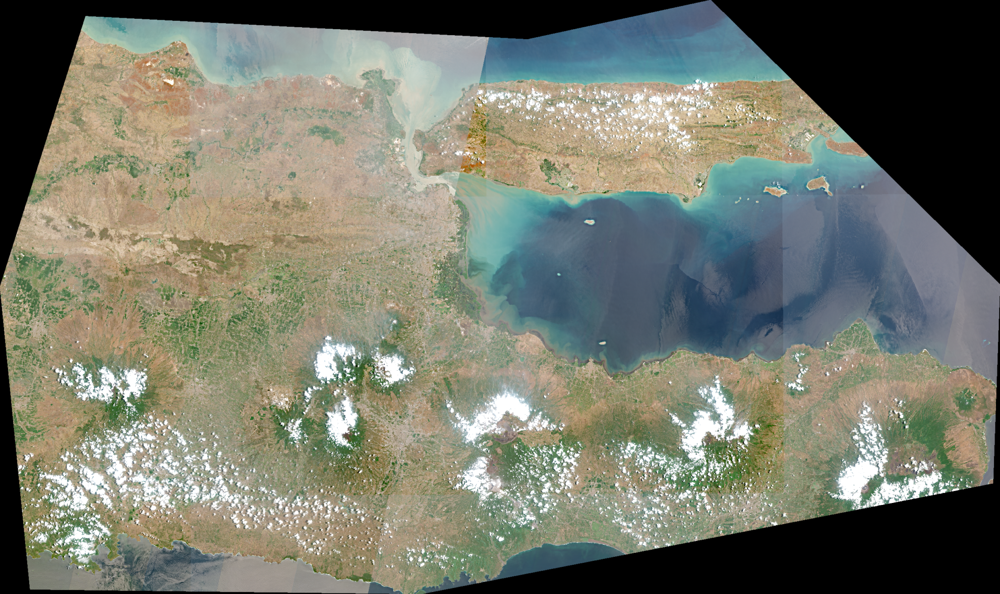

In [ ]:
import folium
import numpy as np
import rasterio
import geopandas as gpd
import base64

from pathlib import Path
from folium.raster_layers import ImageOverlay
from PIL import Image
from io import BytesIO
from IPython.display import display, HTML
from rasterio.enums import Resampling
from rasterio.warp import transform_bounds

# ==========================================
# 1. CARI DAN BACA FILE GEOJSON
# ==========================================
BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "data"

# Cari GeoJSON dengan beberapa kemungkinan nama
kandidat_geojson = [
    DATA_DIR / "jawatimur.geojson",
    BASE_DIR / "jawatimur.geojson",
    DATA_DIR / "jawatimur(5).geojson",
    BASE_DIR / "jawatimur(5).geojson"
]

geojson_path = next(
    (p for p in kandidat_geojson if p.exists()),
    None
)

if geojson_path is None:
    raise FileNotFoundError(
        f"GeoJSON tidak ditemukan. Folder kerja: {BASE_DIR}\n"
        "Letakkan jawatimur.geojson di folder data."
    )

gdf = gpd.read_file(geojson_path)

print("File GeoJSON:", geojson_path)
print("Kolom GeoJSON:", gdf.columns.tolist())

# Cari kolom kelas
if "class" not in gdf.columns:
    kolom_kelas = next(
        (c for c in ["nama", "name", "kelas", "class_name"]
         if c in gdf.columns),
        None
    )

    if kolom_kelas is None:
        raise KeyError(
            "Kolom kelas tidak ditemukan. "
            "Periksa daftar Kolom GeoJSON di atas."
        )

    gdf["class"] = gdf[kolom_kelas]

# Seragamkan penamaan kelas
gdf["class"] = (
    gdf["class"].astype(str).str.strip().str.lower()
    .replace({
        "fram land": "farm land",
        "farmland": "farm land",
        "farm land": "farm land",
        "built-up": "build up",
        "built up": "build up",
        "build-up": "build up",
        "waterbody": "water body",
        "hutan mangrove": "mangrove"
    })
)

if gdf.crs is None:
    raise ValueError(
        "CRS GeoJSON tidak tersedia. "
        "Periksa sistem koordinat file GeoJSON."
    )

gdf = gdf[gdf.geometry.notna() & ~gdf.geometry.is_empty].copy()
gdf = gdf.to_crs(epsg=4326)

# ==========================================
# 2. CARI FILE TRUE COLOR TIFF
# ==========================================
nama_truecolor = (
    "2026-10-01-00_00_2026-10-01-23_59_"
    "Sentinel-2_L2A_True_color(3).tiff"
)

kandidat_tiff = [
    DATA_DIR / nama_truecolor,
    BASE_DIR / nama_truecolor,
    DATA_DIR / "True_color.tif",
    DATA_DIR / "True_Color.tif",
    DATA_DIR / "true_color.tif",
    BASE_DIR / "True_color.tif"
]

truecolor_path = next(
    (p for p in kandidat_tiff if p.exists()),
    None
)

# Pencarian tambahan bila file berada di subfolder proyek
if truecolor_path is None:
    for folder in [DATA_DIR, BASE_DIR]:
        if folder.exists():
            hasil = list(folder.glob("*True*color*.tif*"))
            if hasil:
                truecolor_path = hasil[0]
                break

if truecolor_path is None:
    raise FileNotFoundError(
        "File True Color TIFF tidak ditemukan.\n"
        "Letakkan TIFF True Color di folder data."
    )

print("File True Color:", truecolor_path)

# ==========================================
# 3. WARNA DAN NAMA KELAS
# ==========================================
kelas_warna = {
    "build up": ("Built-up", "#808080"),
    "farm land": ("Farmland", "#FFD700"),
    "water body": ("Water Body", "#2196F3"),
    "forest": ("Forest", "#228B22"),
    "mangrove": ("Mangrove", "#00CED1")
}

print("\nJumlah polygon:", len(gdf))
print("Jumlah per kelas:")
print(gdf["class"].value_counts().to_string())

# ==========================================
# 4. BACA RASTER TRUE COLOR
# ==========================================
with rasterio.open(truecolor_path) as src:
    if src.count < 3:
        raise ValueError(
            "Raster True Color harus memiliki minimal 3 band RGB."
        )

    tinggi = min(src.height, 1200)
    lebar = max(1, int(src.width * tinggi / src.height))

    rgb = src.read(
        [1, 2, 3],
        out_shape=(3, tinggi, lebar),
        resampling=Resampling.bilinear
    ).astype(np.float32)

    # Ubah batas raster menjadi koordinat geografis
    if src.crs is None:
        raise ValueError("CRS raster True Color tidak tersedia.")

    left, bottom, right, top = transform_bounds(
        src.crs,
        "EPSG:4326",
        *src.bounds,
        densify_pts=21
    )

    bounds = [[bottom, left], [top, right]]

    # Mask raster mengikuti ukuran RGB yang sudah diperkecil
    mask_data = src.dataset_mask(
        out_shape=(tinggi, lebar),
        resampling=Resampling.nearest
    )

# Peregangan nilai piksel agar gambar lebih mudah dilihat
rgb_display = np.zeros_like(rgb, dtype=np.uint8)

for i in range(3):
    band = rgb[i]
    valid = band[
        np.isfinite(band) & (mask_data > 0)
    ]

    if valid.size > 0:
        p2, p98 = np.percentile(valid, [2, 98])

        if p98 > p2:
            normalized = np.clip(
                (band - p2) / (p98 - p2), 0, 1
            )
            rgb_display[i] = (
                np.nan_to_num(normalized) * 255
            ).astype(np.uint8)

rgba = np.dstack([
    np.moveaxis(rgb_display, 0, -1),
    np.where(mask_data > 0, 255, 0).astype(np.uint8)
])

buffer = BytesIO()
Image.fromarray(rgba, mode="RGBA").save(
    buffer, format="PNG"
)

image_url = (
    "data:image/png;base64,"
    + base64.b64encode(buffer.getvalue()).decode("utf-8")
)

# ==========================================
# 5. BUAT PETA FOLIUM
# ==========================================
xmin, ymin, xmax, ymax = gdf.total_bounds

m = folium.Map(
    location=[(ymin + ymax) / 2, (xmin + xmax) / 2],
    zoom_start=8,
    tiles="OpenStreetMap",
    control_scale=True
)

# Layer citra Sentinel-2
ImageOverlay(
    image=image_url,
    bounds=bounds,
    name="Sentinel-2 True Color",
    overlay=True,
    control=True,
    show=True,
    opacity=1
).add_to(m)

# ==========================================
# 6. TAMBAHKAN LAYER LIMA KELAS
# ==========================================
for kelas, (nama_tampil, warna) in kelas_warna.items():
    subset = gdf[gdf["class"] == kelas]

    if subset.empty:
        print(f"Peringatan: kelas '{kelas}' tidak ditemukan.")
        continue

    layer = folium.FeatureGroup(
        name=nama_tampil,
        overlay=True,
        show=False
    )

    folium.GeoJson(
        data=subset.to_json(),
        name=nama_tampil,
        style_function=lambda feature, warna=warna: {
            "fillColor": warna,
            "color": warna,
            "weight": 1.5,
            "fillOpacity": 0.45
        },
        tooltip=folium.GeoJsonTooltip(
            fields=["class"],
            aliases=["Kelas:"],
            sticky=True
        )
    ).add_to(layer)

    layer.add_to(m)

# Kontrol untuk mengaktifkan/nonaktifkan layer
folium.LayerControl(
    collapsed=False,
    position="topright"
).add_to(m)

# Sesuaikan tampilan awal dengan cakupan GeoJSON
m.fit_bounds([[ymin, xmin], [ymax, xmax]])

# Tampilkan langsung di bawah sel notebook; tidak menyimpan HTML
display(m)


## Memeriksa cakupan dan nilai band

Cell ini memasangkan nama fitur dengan file TIFF untuk sepuluh band Sentinel-2. Band B04 digunakan sebagai acuan awal untuk memeriksa CRS dan batas raster. Polygon kemudian dibandingkan dengan cakupan citra untuk melihat sampel mana yang beririsan dengan raster.

Bagian berikutnya merangkum resolusi, dimensi, jumlah piksel valid, nilai minimum, maksimum, dan rata-rata tiap band. Informasi ini membantu memastikan file terbaca dan menunjukkan jika karakteristik antarband perlu diperiksa lebih lanjut.

In [ ]:
# PEMERIKSAAN FILE DAN MOSAIK SEMUA TILE PER BAND
from pathlib import Path
import re
import numpy as np
import pandas as pd
import rasterio
from rasterio.merge import merge

BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "data"
OUTPUT_DIR = BASE_DIR / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Kenali nama file band raw Copernicus, termasuk duplikat seperti (1), (2).
BAND_CODES = ["B02", "B03", "B04", "B05", "B06", "B07", "B08", "B8A", "B11", "B12"]

def list_band_tiles(code):
    candidates = []
    for p in list(DATA_DIR.glob("*.tif")) + list(DATA_DIR.glob("*.tiff")):
        name = p.name.upper()
        if code.upper() in name and "RAW" in name and "TRUE_COLOR" not in name:
            candidates.append(p)
    # Unik dan urut
    return sorted(set(candidates), key=lambda p: p.name.lower())

band_tiles = {code: list_band_tiles(code) for code in BAND_CODES}
print("=== TILE YANG DITEMUKAN PER BAND ===")
for code, files in band_tiles.items():
    print(f"{code}: {len(files)} file")
    for p in files:
        print("   -", p.name)

missing = [code for code, files in band_tiles.items() if not files]
if missing:
    raise FileNotFoundError(
        "File raw untuk band berikut tidak ditemukan: " + ", ".join(missing) +
        ". Simpan semua TIFF band Raw di folder data."
    )

# Buat mosaik terpisah untuk tiap band. Rasterio merge menyelaraskan tile
# pada grid band tersebut; B02/B03/B04/B08 biasanya 10 m dan B05/B06/B07/B8A/B11/B12 20 m.
band_files = {}
summary = []
for code, files in band_tiles.items():
    datasets = [rasterio.open(p) for p in files]
    try:
        crs_set = {str(ds.crs) for ds in datasets}
        if len(crs_set) != 1:
            raise ValueError(f"CRS tidak sama pada tile {code}: {crs_set}")
        mosaic, transform = merge(datasets, nodata=datasets[0].nodata)
        profile = datasets[0].profile.copy()
        profile.update(
            driver="GTiff",
            height=mosaic.shape[1],
            width=mosaic.shape[2],
            transform=transform,
            count=1,
            compress="lzw",
            tiled=True
        )
        out_path = OUTPUT_DIR / f"mosaic_{code}.tif"
        with rasterio.open(out_path, "w", **profile) as dst:
            dst.write(mosaic[0], 1)
        band_files[code] = out_path
        with rasterio.open(out_path) as check:
            summary.append({
                "Band": code,
                "Jumlah tile": len(files),
                "CRS": str(check.crs),
                "Dimensi": f"{check.width} x {check.height}",
                "Resolusi": check.res,
                "Bounds": tuple(check.bounds),
                "File mosaik": out_path.name
            })
    finally:
        for ds in datasets:
            ds.close()

print("\n=== RINGKASAN MOSAIK ===")
display(pd.DataFrame(summary))

# Peringatan: bila hanya satu tile per band, mosaik tetap hanya mencakup tile itu.
if all(len(files) == 1 for files in band_tiles.values()):
    print("\nPERINGATAN: hanya satu tile per band ditemukan. Cakupan belum otomatis seluruh Jawa Timur.")
    print("Tambahkan tile tambahan ke folder data, lalu jalankan ulang sel ini.")
else:
    print("\nMosaik dibuat dari semua tile yang ditemukan. Tetap periksa bounds dan cakupan AOI.")

=== PEMERIKSAAN CITRA ===
CRS: EPSG:4326
Dimensi: (1487, 2500)
Bounds: BoundingBox(left=111.4126454, bottom=-8.4407652, right=114.4687288, top=-6.6384739)

=== PEMERIKSAAN POLYGON ===
Jumlah polygon: 262
CRS polygon: GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST],AUTHORITY["EPSG","4326"]]
Kelas:
class
farm land     61
build up      50
mangrove      50
water body    50
forest        50
none           1
Name: count, dtype: int64

Polygon yang beririsan dengan cakupan citra: 260 / 262
Polygon di luar cakupan citra: 2 / 262

Polygon yang beririsan dengan cakupan citra: 260 / 262
Polygon di luar cakupan citra: 2 / 262


,Band,CRS,Resolusi_X,Resolusi_Y,Dimensi,Piksel_valid,Min,Max,Mean
0,B02,EPSG:4326,0.001222,0.001212,2500 x 1487,3717500,0.0,65535.0,5460.719238
1,B03,EPSG:4326,0.001222,0.001212,2500 x 1487,3717500,0.0,65535.0,6092.584961
2,B04,EPSG:4326,0.001222,0.001212,2500 x 1487,3717500,0.0,65535.0,6031.604492
3,B05,EPSG:4326,0.001222,0.001212,2500 x 1487,3717500,0.0,65535.0,7694.435547
4,B06,EPSG:4326,0.001222,0.001212,2500 x 1487,3717500,0.0,65535.0,10217.269531
5,B07,EPSG:4326,0.001222,0.001212,2500 x 1487,3717500,0.0,65535.0,11427.900391
6,B08,EPSG:4326,0.001222,0.001212,2500 x 1487,3717500,0.0,65535.0,11464.221680
7,B8A,EPSG:4326,0.001222,0.001212,2500 x 1487,3717500,0.0,65535.0,12318.978516
8,B11,EPSG:4326,0.001222,0.001212,2500 x 1487,3717500,0.0,65535.0,11071.538086
9,B12,EPSG:4326,0.001222,0.001212,2500 x 1487,3717500,0.0,65535.0,8085.859863


## Cell 8 — Mengambil nilai band pada setiap polygon

Untuk setiap polygon, cell ini mengambil piksel yang berada di dalam area polygon pada masing-masing band. Nilai median piksel digunakan sebagai satu nilai ringkasan untuk polygon tersebut. Dengan cara ini, satu polygon menjadi satu baris data dengan sepuluh fitur spektral dan satu label kelas.

Polygon yang berada di luar raster atau tidak memiliki piksel valid dicatat sebagai gagal. Hasil ekstraksi perlu diperiksa lagi karena sampel yang gagal atau salah label dapat memengaruhi model.

In [ ]:
# CELL 13 — Ekstraksi ulang fitur dengan penanganan polygon di luar raster

import numpy as np
import pandas as pd
import rasterio

from rasterio.mask import mask
from rasterio.errors import WindowError
from shapely.geometry import box

# Definisikan urutan band secara eksplisit
band_order = [
    "B02", "B03", "B04", "B05", "B06",
    "B07", "B08", "B8A", "B11", "B12"
]

# Pastikan variabel yang dibutuhkan tersedia
assert "gdf_check" in globals(), "gdf_check belum tersedia. Jalankan sel pembentukan data polygon."
assert "band_files" in globals(), "band_files belum tersedia. Jalankan sel pemetaan file raster."

# Periksa apakah semua band tersedia
band_hilang = [b for b in band_order if b not in band_files]
if band_hilang:
    raise KeyError(f"Band belum tersedia di band_files: {band_hilang}")

fitur_baru = []

for idx, row in gdf_check.iterrows():
    record = {
        "polygon_id": idx,
        "class": row["class"]
    }

    jumlah_piksel_valid = []
    alasan = []

    geom = row.geometry

    for band_name in band_order:
        path = band_files[band_name]

        try:
            with rasterio.open(path) as src:
                # Periksa apakah CRS polygon sesuai dengan CRS raster
                if gdf_check.crs is None:
                    raise ValueError("CRS gdf_check belum ditentukan")

                if gdf_check.crs != src.crs:
                    raise ValueError(
                        f"CRS polygon ({gdf_check.crs}) berbeda "
                        f"dengan CRS raster ({src.crs})"
                    )

                raster_box = box(
                    src.bounds.left,
                    src.bounds.bottom,
                    src.bounds.right,
                    src.bounds.top
                )

                if not geom.intersects(raster_box):
                    record[band_name] = np.nan
                    jumlah_piksel_valid.append(0)
                    alasan.append(f"{band_name}: di luar raster")
                    continue

                arr, _ = mask(
                    src,
                    [geom.__geo_interface__],
                    crop=True,
                    all_touched=True,
                    filled=False
                )

                values = arr[0].compressed().astype(np.float64)
                values = values[np.isfinite(values)]

                if src.nodata is not None:
                    values = values[values != src.nodata]

                # Hilangkan nilai nol dan nilai khusus pada citra
                values = values[
                    (values > 0) & (values < 65535)
                ]

                jumlah_piksel_valid.append(values.size)

                if values.size > 0:
                    record[band_name] = float(np.median(values))
                else:
                    record[band_name] = np.nan
                    alasan.append(f"{band_name}: tanpa piksel valid")

        except (ValueError, WindowError) as e:
            record[band_name] = np.nan
            jumlah_piksel_valid.append(0)
            alasan.append(f"{band_name}: {e}")

    record["jumlah_piksel_valid_min"] = min(jumlah_piksel_valid)
    record["valid"] = all(n > 0 for n in jumlah_piksel_valid)
    record["catatan"] = "; ".join(alasan)

    fitur_baru.append(record)

df_fitur = pd.DataFrame(fitur_baru)

print("Total polygon:", len(df_fitur))

print("\nStatus ekstraksi:")
display(df_fitur["valid"].value_counts().to_frame("jumlah"))

print("\nHasil per kelas:")
display(
    df_fitur.groupby("class")["valid"]
    .agg(jumlah="count", valid="sum")
)

print("\nPolygon yang gagal:")
display(
    df_fitur.loc[
        ~df_fitur["valid"],
        ["polygon_id", "class", "catatan"]
    ].head(20)
)

Total polygon: 262

Status ekstraksi:


,jumlah
valid,
True,260
False,2



Hasil per kelas:


,jumlah,valid
class,,
build up,50,50
farm land,61,61
forest,50,50
mangrove,50,50
none,1,1
water body,50,48



Polygon yang gagal:


,polygon_id,class,catatan
99,99,water body,B02: di luar raster; B03: di luar raster; B04:...
100,100,water body,B02: di luar raster; B03: di luar raster; B04:...


## Cell 9 — Membersihkan tabel fitur

Cell ini menyaring hasil ekstraksi sebelum dipakai melatih model. Baris yang labelnya bukan salah satu dari lima kelas, ekstraksinya gagal, atau masih memiliki nilai fitur kosong/tidak valid akan dibuang.

Jumlah data sebelum dan sesudah penyaringan serta distribusi kelas ditampilkan supaya perubahan jumlah sampel terlihat. Jika jumlah data berkurang banyak, penyebabnya sebaiknya diperiksa, bukan langsung diabaikan.

In [ ]:

# CELL 14 — Pembersihan dataset fitur

import numpy as np
import pandas as pd

kelas_diizinkan = [
    "build up",
    "farm land",
    "water body",
    "forest",
    "mangrove"
]

# Gunakan hasil ekstraksi terbaru
df_model = df_fitur.copy()

# Normalisasi label kelas
df_model["class"] = (
    df_model["class"]
    .astype("string")
    .str.strip()
    .str.lower()
)

print("Jumlah sebelum pembersihan:", len(df_model))
print("\nLabel kelas sebelum pembersihan:")
print(df_model["class"].value_counts(dropna=False))

# Pertahankan hanya lima kelas yang ditetapkan
df_model = df_model[
    df_model["class"].isin(kelas_diizinkan)
].copy()

# Pertahankan baris dengan fitur lengkap dan status valid
kolom_fitur = [
    "B02", "B03", "B04", "B05", "B06",
    "B07", "B08", "B8A", "B11", "B12"
]

df_model = df_model[
    df_model["valid"].eq(True)
    & df_model[kolom_fitur].notna().all(axis=1)
].copy()

# Pastikan semua nilai fitur numerik dan finite
df_model = df_model[
    np.isfinite(df_model[kolom_fitur]).all(axis=1)
].copy()

print("\nJumlah data siap training:", len(df_model))
print("\nDistribusi kelas:")
display(
    df_model["class"]
    .value_counts()
    .rename("jumlah")
    .to_frame()
)

print("\nContoh dataset:")
display(df_model[["polygon_id", "class"] + kolom_fitur].head())


Jumlah sebelum pembersihan: 262

Label kelas sebelum pembersihan:
class
farm land     61
build up      50
mangrove      50
water body    50
forest        50
none           1
Name: count, dtype: Int64

Jumlah data siap training: 259

Distribusi kelas:


,jumlah
class,
farm land,61
build up,50
mangrove,50
forest,50
water body,48



Contoh dataset:


,polygon_id,class,B02,B03,B04,B05,B06,B07,B08,B8A,B11,B12
0,0,build up,6121.0,7976.0,9797.0,11993.0,14418.0,15879.0,13880.0,17504.0,22433.0,19136.0
1,1,build up,4905.5,7563.0,9912.0,12238.5,15217.0,16845.5,14876.5,17940.5,20768.0,16760.5
2,2,build up,5020.0,7576.0,10164.0,12740.0,15656.0,17432.0,16744.0,18579.0,21017.0,17065.0
3,3,build up,4417.0,6966.0,8710.0,12176.0,17406.0,19988.0,18461.0,21207.0,23573.0,17681.0
4,4,build up,4791.0,7576.0,10164.0,12740.0,15433.0,16875.0,15873.0,17970.0,21017.0,17065.0


## Cell 10 — Membagi data

Kolom band dijadikan fitur (`X`), sedangkan kolom `class` menjadi target (`y`). Data dibagi menjadi 80% untuk training dan 20% untuk testing.

`stratify=y` membantu menjaga proporsi tiap kelas di kedua bagian, dan `random_state=42` membuat pembagian bisa diulang. Data testing disimpan untuk mengecek kinerja model pada sampel yang tidak dipakai saat pelatihan.

In [ ]:

# CELL 15 — Pembagian data training dan testing

from sklearn.model_selection import train_test_split

# Fitur spektral
kolom_fitur = [
    "B02", "B03", "B04", "B05", "B06",
    "B07", "B08", "B8A", "B11", "B12"
]

X = df_model[kolom_fitur].copy()
y = df_model["class"].copy()

# Bagi data 80% training dan 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Jumlah seluruh data :", len(X))
print("Data training       :", len(X_train))
print("Data testing        :", len(X_test))

print("\nDistribusi kelas data training:")
display(y_train.value_counts().sort_index().to_frame("jumlah"))

print("\nDistribusi kelas data testing:")
display(y_test.value_counts().sort_index().to_frame("jumlah"))


Jumlah seluruh data : 259
Data training       : 207
Data testing        : 52

Distribusi kelas data training:


,jumlah
class,
build up,40
farm land,49
forest,40
mangrove,40
water body,38



Distribusi kelas data testing:


,jumlah
class,
build up,10
farm land,12
forest,10
mangrove,10
water body,10


## Cell 11 — Melatih Random Forest

Cell ini melatih model Random Forest menggunakan sepuluh fitur band. Model dibuat dengan 300 pohon keputusan. Pengaturan `class_weight="balanced"` membantu memberi bobot lebih besar pada kelas yang jumlah sampelnya lebih sedikit.

Setelah `fit()` selesai, model siap digunakan untuk memprediksi data testing dan mengklasifikasikan piksel raster. Keberhasilan menjalankan training belum berarti hasil model sudah akurat; hal itu dilihat dari evaluasi berikutnya.

In [ ]:

# CELL 16 — Training Random Forest

from sklearn.ensemble import RandomForestClassifier

model_rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model_rf.fit(X_train, y_train)

print("Training Random Forest berhasil.")
print("Jumlah pohon:", model_rf.n_estimators)
print("Jumlah fitur:", model_rf.n_features_in_)


Training Random Forest berhasil.
Jumlah pohon: 300
Jumlah fitur: 10


## Cell 12 — Evaluasi awal model

Model memprediksi kelas pada data testing, lalu hasilnya dibandingkan dengan label sebenarnya. Cell ini menampilkan accuracy, precision, recall, F1-score, dan confusion matrix.

Confusion matrix membantu melihat kelas mana yang sering tertukar, misalnya apakah sampel forest sering diprediksi sebagai mangrove. Angka evaluasi yang dilaporkan harus diambil dari hasil run notebook, bukan diisi berdasarkan perkiraan.

EVALUASI MODEL RANDOM FOREST
Akurasi testing: 0.6923
Akurasi persen : 69.23%

Classification Report:
              precision    recall  f1-score   support

    build up     0.3750    0.3000    0.3333        10
   farm land     0.5385    0.5833    0.5600        12
      forest     0.7500    0.9000    0.8182        10
    mangrove     1.0000    0.9000    0.9474        10
  water body     0.8000    0.8000    0.8000        10

    accuracy                         0.6923        52
   macro avg     0.6927    0.6967    0.6918        52
weighted avg     0.6868    0.6923    0.6867        52



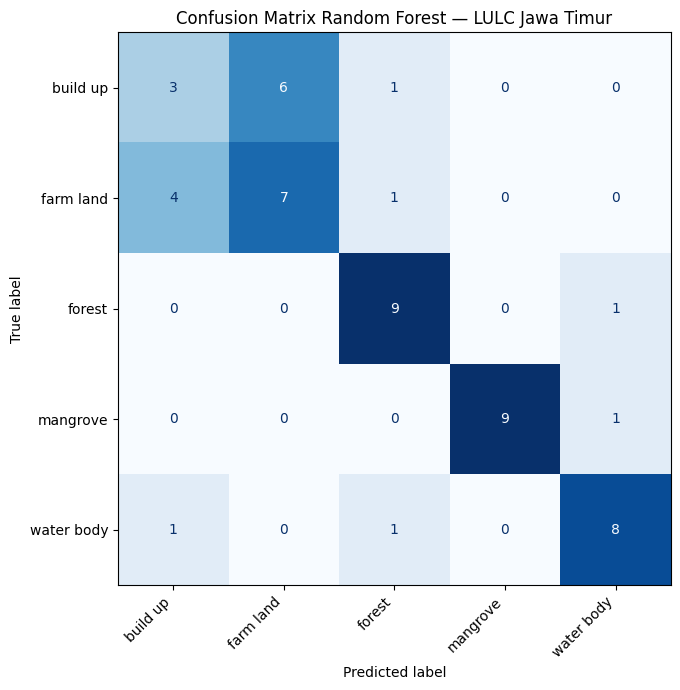

In [ ]:

# CELL 17 — Evaluasi model Random Forest

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import pandas as pd

# Prediksi data testing
y_pred = model_rf.predict(X_test)

# Hitung akurasi
akurasi = accuracy_score(y_test, y_pred)

print("=" * 45)
print("EVALUASI MODEL RANDOM FOREST")
print("=" * 45)
print(f"Akurasi testing: {akurasi:.4f}")
print(f"Akurasi persen : {akurasi * 100:.2f}%")

# Evaluasi setiap kelas
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=model_rf.classes_,
        zero_division=0,
        digits=4
    )
)

# Confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model_rf.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model_rf.classes_
)

fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title("Confusion Matrix Random Forest — LULC Jawa Timur")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## Cell 13 — Melihat pengaruh setiap band

Random Forest menyediakan nilai `feature_importances_` untuk melihat fitur yang paling banyak membantu pemisahan kelas dalam model. Cell ini mengurutkan nilai tersebut dan menampilkannya dalam grafik.

Hasilnya dapat menjadi petunjuk band mana yang berguna pada dataset ini. Namun, nilai importance bukan bukti bahwa suatu band selalu paling baik di semua wilayah; hasilnya bergantung pada sampel dan model yang digunakan.

Peringkat kepentingan fitur:


,Band,Importance
0,B11,0.192526
1,B12,0.174195
2,B8A,0.120419
3,B06,0.090440
4,B07,0.089642
5,B05,0.077624
6,B03,0.068940
7,B08,0.068933
8,B02,0.066739
9,B04,0.050542


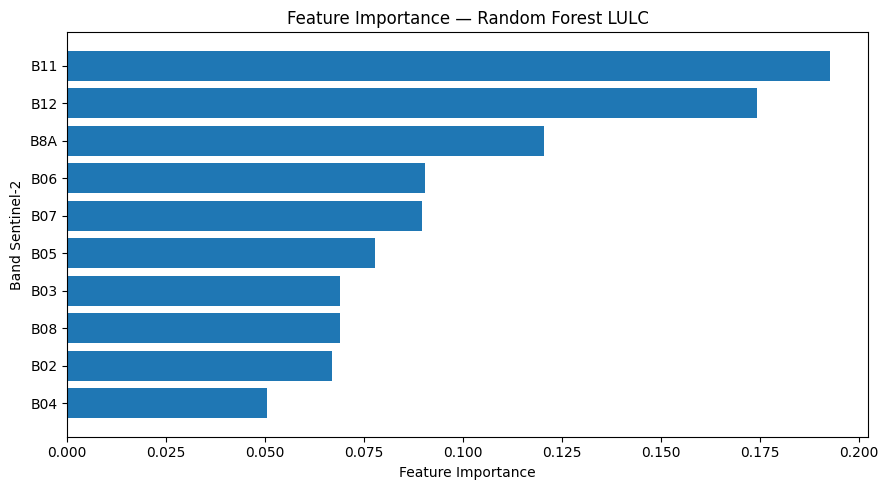

In [ ]:

# CELL 18 — Analisis feature importance Random Forest

import pandas as pd
import matplotlib.pyplot as plt

importance_df = pd.DataFrame({
    "Band": kolom_fitur,
    "Importance": model_rf.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
)

print("Peringkat kepentingan fitur:")
display(importance_df.reset_index(drop=True))

# Visualisasi
plt.figure(figsize=(9, 5))

plt.barh(
    importance_df["Band"],
    importance_df["Importance"]
)

plt.gca().invert_yaxis()
plt.xlabel("Feature Importance")
plt.ylabel("Band Sentinel-2")
plt.title("Feature Importance — Random Forest LULC")
plt.tight_layout()
plt.show()


## Cell 14 — Validasi silang

Cell ini membagi data training menjadi lima bagian secara bergantian. Pada setiap putaran, empat bagian dipakai untuk melatih model dan satu bagian untuk validasi. Proporsi kelas dijaga dengan `StratifiedKFold`.

Accuracy, macro F1, dan balanced accuracy dihitung untuk setiap fold. Rata-rata dan standar deviasi membantu melihat apakah hasil model cukup konsisten pada pembagian data yang berbeda. Data testing utama tidak digunakan pada proses ini.

In [ ]:

# CELL 19 — Cross-validation Random Forest

import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier

# Gunakan data training saja agar data testing tetap independen
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

model_cv = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

hasil_cv = cross_validate(
    model_cv,
    X_train,
    y_train,
    cv=cv,
    scoring=["accuracy", "f1_macro", "balanced_accuracy"],
    n_jobs=-1
)

hasil_cv_df = pd.DataFrame({
    "Fold": range(1, 6),
    "Accuracy": hasil_cv["test_accuracy"],
    "F1 Macro": hasil_cv["test_f1_macro"],
    "Balanced Accuracy": hasil_cv["test_balanced_accuracy"]
})

display(hasil_cv_df.round(4))

print("\nRata-rata hasil validasi silang:")
print(hasil_cv_df.mean(numeric_only=True).round(4))

print("\nStandar deviasi:")
print(hasil_cv_df.std(numeric_only=True).round(4))


,Fold,Accuracy,F1 Macro,Balanced Accuracy
0,1,0.7143,0.7109,0.7100
1,2,0.8571,0.8678,0.8650
2,3,0.8537,0.8516,0.8500
3,4,0.7073,0.6974,0.7057
4,5,0.7561,0.7408,0.7443



Rata-rata hasil validasi silang:
Fold                 3.0000
Accuracy             0.7777
F1 Macro             0.7737
Balanced Accuracy    0.7750
dtype: float64

Standar deviasi:
Fold                 1.5811
Accuracy             0.0734
F1 Macro             0.0803
Balanced Accuracy    0.0770
dtype: float64


## Cell 15 — Ringkasan evaluasi testing

Cell ini kembali menghitung metrik pada data testing, termasuk balanced accuracy dan macro F1. Keduanya melengkapi accuracy, terutama saat jumlah sampel tiap kelas tidak sama.

Cell ini sebagian mengulang evaluasi di cell sebelumnya, tetapi menampilkan ringkasan metrik yang lebih singkat. Untuk laporan, cukup gunakan satu set angka evaluasi yang konsisten dan jelaskan bahwa hasil berasal dari data testing yang sama.

=== EVALUASI AKHIR RANDOM FOREST ===
Accuracy           : 0.6923
Balanced Accuracy  : 0.6967
F1 Macro            : 0.6918

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    build up       0.38      0.30      0.33        10
   farm land       0.54      0.58      0.56        12
      forest       0.75      0.90      0.82        10
    mangrove       1.00      0.90      0.95        10
  water body       0.80      0.80      0.80        10

    accuracy                           0.69        52
   macro avg       0.69      0.70      0.69        52
weighted avg       0.69      0.69      0.69        52



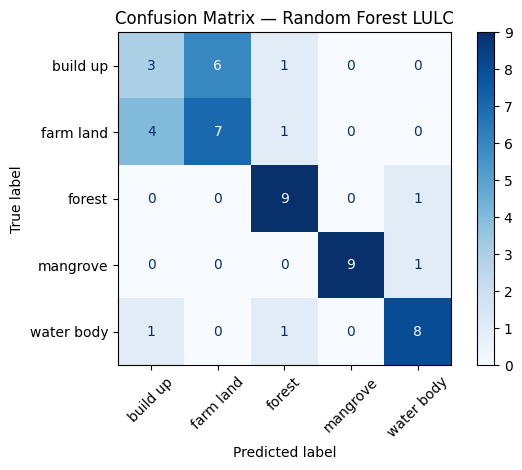

In [ ]:

# CELL 20 — Evaluasi akhir pada data testing

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Prediksi menggunakan model Random Forest yang sudah dilatih
y_pred = model_rf.predict(X_test)

# Metrik evaluasi
print("=== EVALUASI AKHIR RANDOM FOREST ===")
print(f"Accuracy           : {accuracy_score(y_test, y_pred):.4f}")
print(f"Balanced Accuracy  : {balanced_accuracy_score(y_test, y_pred):.4f}")
print(f"F1 Macro            : {f1_score(y_test, y_pred, average='macro'):.4f}")

print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    xticks_rotation=45,
    cmap="Blues",
    values_format="d"
)

plt.title("Confusion Matrix — Random Forest LULC")
plt.tight_layout()
plt.show()


## Pemeriksaan sebelum klasifikasi seluruh wilayah

Raster klasifikasi mengikuti footprint mosaik band acuan B04. Bila mosaik belum menutupi seluruh AOI, output juga belum menutupi seluruh Jawa Timur. Jangan menganggap `clip` pada sampel polygon sebagai batas provinsi. Untuk keluaran akhir, gunakan file batas administrasi Jawa Timur yang terpisah (GeoJSON/Shapefile) untuk memotong raster dan peta Streamlit.

Sebelum menjalankan sel klasifikasi, pastikan semua band mosaik menutupi AOI yang sama, sampel yang dipakai berada di dalam cakupan citra, dan label mangrove terwakili. Akurasi di atas 70% adalah target, bukan angka yang boleh ditetapkan manual; laporkan metrik yang benar-benar dihasilkan data uji.


## Cell 16 — Menerapkan model ke raster

Cell ini menggunakan Random Forest yang sudah dilatih untuk memprediksi kelas pada piksel citra. Urutan fitur raster harus sama dengan urutan band saat training. Piksel yang memiliki nilai tidak valid pada salah satu band tidak diprediksi.

Hasil prediksi disimpan sebagai GeoTIFF dengan kode angka untuk masing-masing kelas dan nilai 0 untuk NoData. Band Sentinel-2 memiliki resolusi yang berbeda, sehingga sebelum digabungkan semua band harus diselaraskan ke grid raster acuan. Versi kode yang diperbaiki melakukan penyelarasan ini agar pemeriksaan dimensi tidak langsung gagal.

In [ ]:
# CELL 22 — Klasifikasi Raster LULC Jawa Timur

import numpy as np
import rasterio
import pandas as pd
from pathlib import Path
from rasterio.warp import reproject, Resampling

# Urutan fitur harus sama dengan saat model dilatih
band_order = list(X_train.columns)

OUTPUT_DIR = Path(OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Gunakan grid B04 sebagai acuan. Band 10 m dan 20 m perlu diselaraskan.
with rasterio.open(band_files["B04"]) as ref:
    profile = ref.profile.copy()
    height, width = ref.height, ref.width
    transform, crs = ref.transform, ref.crs

features = []
valid_pixels = np.ones((height, width), dtype=bool)

for band_name in band_order:
    with rasterio.open(band_files[band_name]) as src:
        if src.crs is None or crs is None:
            raise ValueError(f"CRS tidak tersedia pada band {band_name}.")

        # Baca sebagai float agar nilai NoData dapat ditangani
        source = src.read(1, masked=True).astype(np.float32).filled(np.nan)
        source[~np.isfinite(source) | (source == 0)] = np.nan

        # Selaraskan band ke ukuran, CRS, dan transformasi B04
        aligned = np.full((height, width), np.nan, dtype=np.float32)

        reproject(
            source=source,
            destination=aligned,
            src_transform=src.transform,
            src_crs=src.crs,
            src_nodata=np.nan,
            dst_transform=transform,
            dst_crs=crs,
            dst_nodata=np.nan,
            resampling=Resampling.bilinear
        )

        features.append(aligned)
        valid_pixels &= np.isfinite(aligned) & (aligned > 0)

# Bentuk array: baris = piksel, kolom = band
stack = np.stack(features, axis=-1)
X_image = stack.reshape(-1, len(band_order))
valid_flat = valid_pixels.ravel()
valid_flat &= np.isfinite(X_image).all(axis=1)

print("Grid acuan: B04")
print("Dimensi raster:", width, "x", height)
print("Total piksel:", height * width)
print("Piksel valid:", int(valid_flat.sum()))
print("Piksel diabaikan:", int((~valid_flat).sum()))

if not valid_flat.any():
    raise ValueError(
        "Tidak ada piksel valid. Periksa band, nilai NoData, dan cakupan citra."
    )

# Kode kelas mengikuti urutan kelas model
classes = list(model_rf.classes_)
class_to_id = {name: i + 1 for i, name in enumerate(classes)}

prediction = np.zeros(height * width, dtype=np.uint8)
valid_indices = np.flatnonzero(valid_flat)
batch_size = 100_000

for start in range(0, len(valid_indices), batch_size):
    idx = valid_indices[start:start + batch_size]
    batch = pd.DataFrame(X_image[idx], columns=band_order)
    predicted_labels = model_rf.predict(batch)

    prediction[idx] = np.array(
        [class_to_id[label] for label in predicted_labels],
        dtype=np.uint8
    )

    print(
        f"Prediksi: {min(start + batch_size, len(valid_indices)):,}"
        f" / {len(valid_indices):,} piksel"
    )

prediction = prediction.reshape(height, width)

output_tif = OUTPUT_DIR / "LULC_Jawa_Timur_RandomForest.tif"

profile.update(
    driver="GTiff",
    height=height,
    width=width,
    transform=transform,
    crs=crs,
    count=1,
    dtype="uint8",
    nodata=0,
    compress="lzw"
)

with rasterio.open(output_tif, "w", **profile) as dst:
    dst.write(prediction, 1)

print("\\nKlasifikasi selesai.")
print("File hasil:", output_tif)
print("Kode kelas:")
for label, code in class_to_id.items():
    print(f"{code} = {label}")


Grid acuan: B04
Dimensi raster: 2500 x 1487
Total piksel: 3717500
Piksel valid: 3033280
Piksel diabaikan: 684220
Prediksi: 100,000 / 3,033,280 piksel
Prediksi: 200,000 / 3,033,280 piksel
Prediksi: 300,000 / 3,033,280 piksel
Prediksi: 400,000 / 3,033,280 piksel
Prediksi: 500,000 / 3,033,280 piksel
Prediksi: 600,000 / 3,033,280 piksel
Prediksi: 700,000 / 3,033,280 piksel
Prediksi: 800,000 / 3,033,280 piksel
Prediksi: 900,000 / 3,033,280 piksel
Prediksi: 1,000,000 / 3,033,280 piksel
Prediksi: 1,100,000 / 3,033,280 piksel
Prediksi: 1,200,000 / 3,033,280 piksel
Prediksi: 1,300,000 / 3,033,280 piksel
Prediksi: 1,400,000 / 3,033,280 piksel
Prediksi: 1,500,000 / 3,033,280 piksel
Prediksi: 1,600,000 / 3,033,280 piksel
Prediksi: 1,700,000 / 3,033,280 piksel
Prediksi: 1,800,000 / 3,033,280 piksel
Prediksi: 1,900,000 / 3,033,280 piksel
Prediksi: 2,000,000 / 3,033,280 piksel
Prediksi: 2,100,000 / 3,033,280 piksel
Prediksi: 2,200,000 / 3,033,280 piksel
Prediksi: 2,300,000 / 3,033,280 piksel
Prediksi

## Cell 17 — Menghitung sebaran kelas hasil raster

Cell ini membaca GeoTIFF hasil klasifikasi dan menghitung jumlah piksel untuk setiap kode kelas. Persentase dihitung dari jumlah piksel yang masuk ke lima kelas, sedangkan piksel NoData dihitung terpisah.

Tabel dan peta warna memberi gambaran sebaran hasil prediksi. Angka tersebut belum bisa langsung disebut luas resmi tutupan lahan Jawa Timur, karena raster perlu dipotong dengan batas wilayah yang benar dan luas perlu dihitung sesuai sistem koordinat serta resolusi raster.

CRS: EPSG:4326
Dimensi: 2500 x 1487
NoData: 0.0
Resolusi: (0.0012224333599999966, 0.001212031809011432)

Distribusi kelas hasil klasifikasi:


,Kode,Kelas,Jumlah piksel,Persentase (%)
0,1,Build up,130439,4.30
1,2,Farm land,172153,5.68
2,3,Forest,1150140,37.92
3,4,Mangrove,147219,4.85
4,5,Water body,1433329,47.25



Piksel NoData: 684220
Nilai raster unik: [0 1 2 3 4 5]


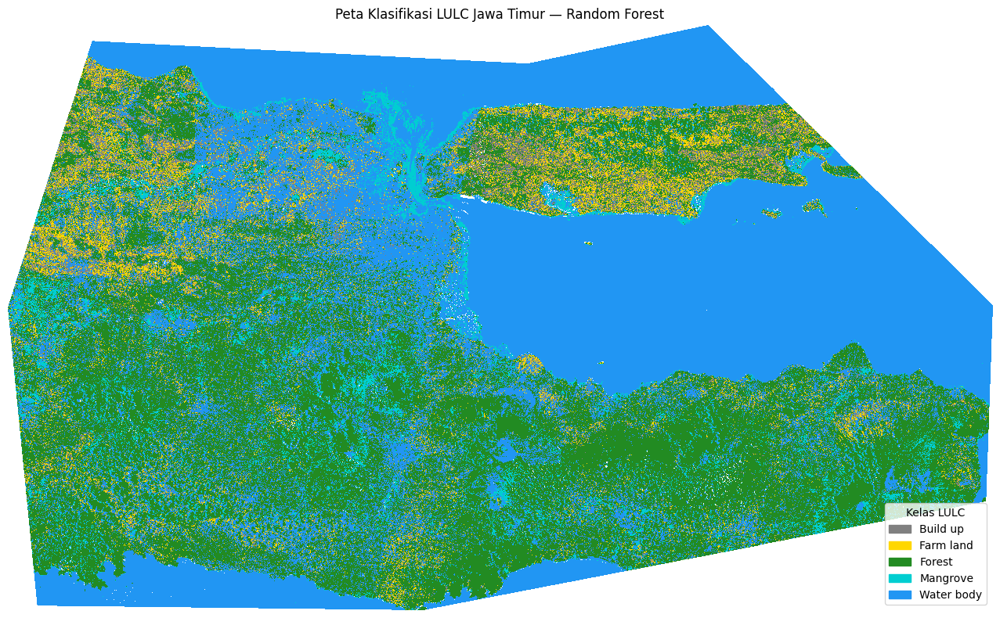

In [ ]:

# CELL 23 — Validasi hasil klasifikasi raster

import numpy as np
import rasterio
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

output_tif = OUTPUT_DIR / "LULC_Jawa_Timur_RandomForest.tif"

nama_kelas = {
    1: "Build up",
    2: "Farm land",
    3: "Forest",
    4: "Mangrove",
    5: "Water body"
}

warna_kelas = {
    1: "#808080",
    2: "#FFD700",
    3: "#228B22",
    4: "#00CED1",
    5: "#2196F3"
}

with rasterio.open(output_tif) as src:
    lulc = src.read(1)
    print("CRS:", src.crs)
    print("Dimensi:", src.width, "x", src.height)
    print("NoData:", src.nodata)
    print("Resolusi:", src.res)

# Hitung piksel setiap kelas
hasil = []

for kode, nama in nama_kelas.items():
    jumlah = int(np.count_nonzero(lulc == kode))
    hasil.append({
        "Kode": kode,
        "Kelas": nama,
        "Jumlah piksel": jumlah
    })

df_lulc = pd.DataFrame(hasil)
total_valid = int(df_lulc["Jumlah piksel"].sum())

df_lulc["Persentase (%)"] = (
    (df_lulc["Jumlah piksel"] / total_valid * 100).round(2)
    if total_valid else 0
)

print("\nDistribusi kelas hasil klasifikasi:")
display(df_lulc)

print("\nPiksel NoData:", int(np.count_nonzero(lulc == 0)))
print("Nilai raster unik:", np.unique(lulc))

# Visualisasi raster klasifikasi
cmap = ListedColormap([
    warna_kelas[i] for i in range(1, 6)
])

plt.figure(figsize=(14, 8))
plt.imshow(
    np.ma.masked_equal(lulc, 0),
    cmap=cmap,
    vmin=1,
    vmax=5,
    interpolation="nearest"
)

legend_items = [
    Patch(color=warna_kelas[k], label=nama_kelas[k])
    for k in nama_kelas
]

plt.legend(
    handles=legend_items,
    loc="lower right",
    title="Kelas LULC"
)

plt.title("Peta Klasifikasi LULC Jawa Timur — Random Forest")
plt.axis("off")
plt.tight_layout()
plt.show()


## Cell 18 — Membandingkan True Color dan hasil klasifikasi

Cell ini menampilkan citra True Color dan raster hasil klasifikasi berdampingan. Tujuannya untuk memeriksa secara visual apakah pola kelas yang diprediksi terlihat masuk akal dibandingkan citra.

Plot perlu menggunakan CRS dan batas koordinat yang sesuai. Jika citra True Color dan raster klasifikasi mempunyai grid berbeda, perbandingan berdampingan ini hanya bersifat visual dan bukan evaluasi akurasi. Akurasi tetap mengacu pada data referensi dan metrik pengujian.

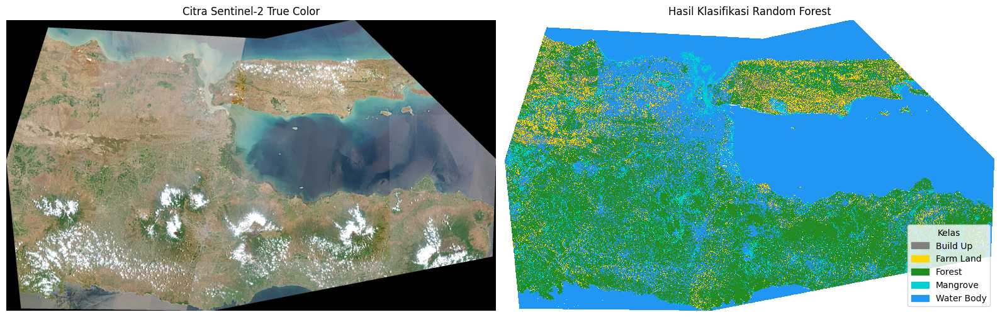

In [ ]:
# CELL 27 — Membandingkan citra asli dan hasil klasifikasi

import matplotlib.pyplot as plt
import rasterio
import numpy as np
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# Baca dan normalisasi True Color untuk tampilan
with rasterio.open(truecolor_path) as src:
    rgb = src.read([1, 2, 3]).astype(np.float32)

rgb_display = np.zeros_like(rgb, dtype=np.float32)
for i in range(3):
    band = rgb[i]
    valid = band[np.isfinite(band)]
    if valid.size:
        p2, p98 = np.percentile(valid, [2, 98])
        if p98 > p2:
            rgb_display[i] = np.clip((band - p2) / (p98 - p2), 0, 1)

# Baca raster hasil klasifikasi
with rasterio.open(output_tif) as src:
    hasil = src.read(1)
    hasil = np.ma.masked_equal(hasil, 0)

# Urutan kode sesuai model.classes_ yang digunakan saat penyimpanan
kelas_model = list(model_rf.classes_)
warna = {
    "build up": "#808080",
    "farm land": "#FFD700",
    "forest": "#228B22",
    "mangrove": "#00CED1",
    "water body": "#2196F3"
}
warna_urut = [warna[k] for k in kelas_model]
cmap = ListedColormap(warna_urut)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

axes[0].imshow(np.moveaxis(rgb_display, 0, -1))
axes[0].set_title("Citra Sentinel-2 True Color")
axes[0].axis("off")

im = axes[1].imshow(
    hasil,
    interpolation="nearest",
    cmap=cmap,
    vmin=1,
    vmax=len(kelas_model)
)
axes[1].set_title("Hasil Klasifikasi Random Forest")
axes[1].axis("off")

legend_items = [
    Patch(color=warna[k], label=k.title())
    for k in kelas_model
]
axes[1].legend(handles=legend_items, loc="lower right", title="Kelas")

plt.tight_layout()
plt.show()


## link streamlit

https://lulcjawatimur.streamlit.app/